## 1. Install required packages

In [1]:
!pip install -q ultralytics opencv-python

## 2. Import libraries

In [2]:
import os
from pathlib import Path

import cv2
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO
from google.colab import drive

print("OpenCV version:", cv2.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
OpenCV version: 5.0.0


## 3. Mount Google Drive

In [3]:
drive.mount('/content/drive')

Mounted at /content/drive


## 4. Define project paths

In [4]:
BASE_DIR = Path("/content/drive/MyDrive/cheating tracking")
VIDEO_DIR = BASE_DIR / "videos"
OUTPUT_DIR = BASE_DIR / "outputs"
DETECTION_OUTPUT_DIR = OUTPUT_DIR / "detection"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DETECTION_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("BASE_DIR:", BASE_DIR)
print("VIDEO_DIR:", VIDEO_DIR)
print("DETECTION_OUTPUT_DIR:", DETECTION_OUTPUT_DIR)

BASE_DIR: /content/drive/MyDrive/cheating tracking
VIDEO_DIR: /content/drive/MyDrive/cheating tracking/videos
DETECTION_OUTPUT_DIR: /content/drive/MyDrive/cheating tracking/outputs/detection


## 5. Check uploaded videos

In [5]:
video_files = sorted(
    list(VIDEO_DIR.glob("*.mp4")) +
    list(VIDEO_DIR.glob("*.avi")) +
    list(VIDEO_DIR.glob("*.mov")) +
    list(VIDEO_DIR.glob("*.mkv"))
)

print(f"Number of videos found: {len(video_files)}")

for video in video_files:
    print(" -", video.name)

assert len(video_files) > 0, (
    "No videos were found. Check that your Drive path is exactly: "
    "/content/drive/MyDrive/cheating tracking/videos"
)

Number of videos found: 4
 - video1.mp4
 - video2.mp4
 - video3.mp4
 - video4.mp4


## 6. Extract video metadata

In [6]:
def get_video_info(video_path):
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        return {
            "video": video_path.name,
            "status": "Cannot open",
            "fps": None,
            "frames": None,
            "duration_sec": None,
            "width": None,
            "height": None,
        }

    fps = cap.get(cv2.CAP_PROP_FPS)
    frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    duration = frames / fps if fps and fps > 0 else 0

    cap.release()

    return {
        "video": video_path.name,
        "status": "OK",
        "fps": round(fps, 2),
        "frames": frames,
        "duration_sec": round(duration, 2),
        "width": width,
        "height": height,
    }

video_info = pd.DataFrame([get_video_info(v) for v in video_files])
video_info

,video,status,fps,frames,duration_sec,width,height
0,video1.mp4,OK,24.00,488,20.33,768,432
1,video2.mp4,OK,23.98,261,10.89,768,432
2,video3.mp4,OK,23.98,256,10.68,768,432
3,video4.mp4,OK,23.98,226,9.43,768,432


## 7. Display one sample frame from each video

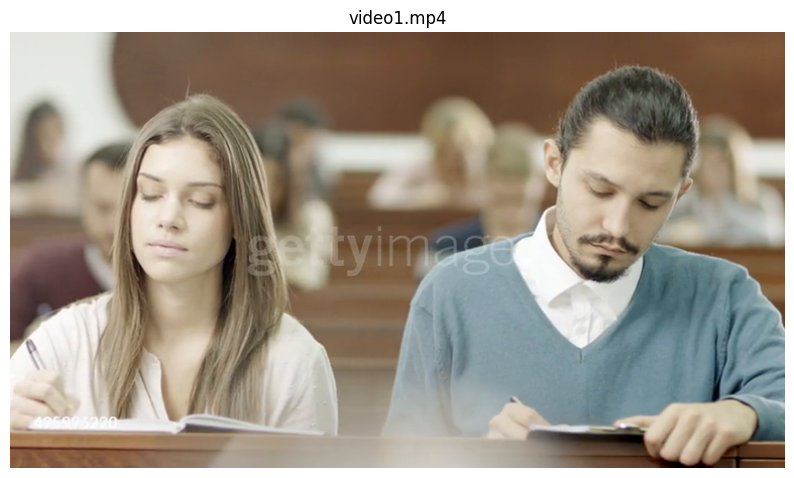

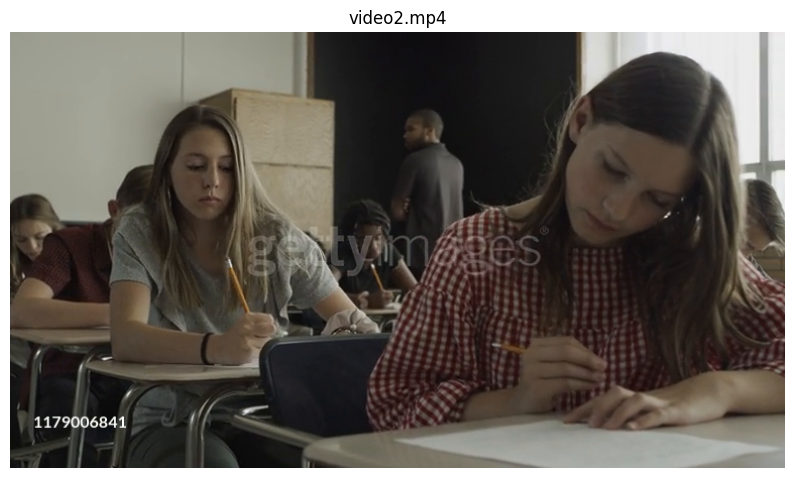

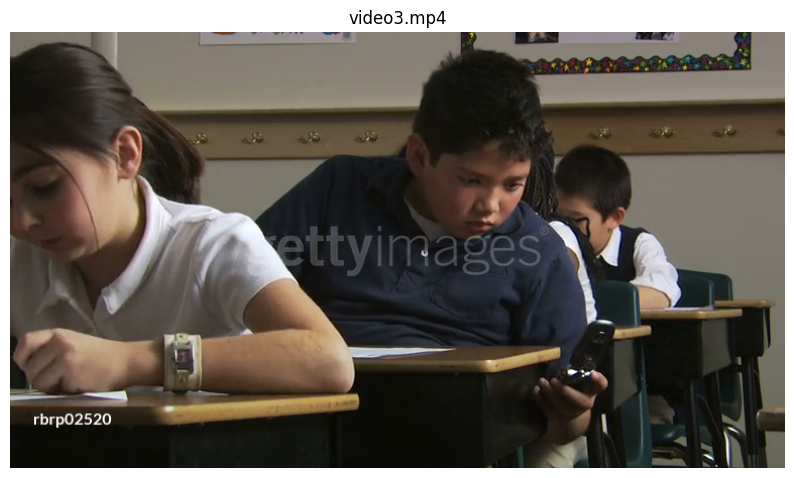

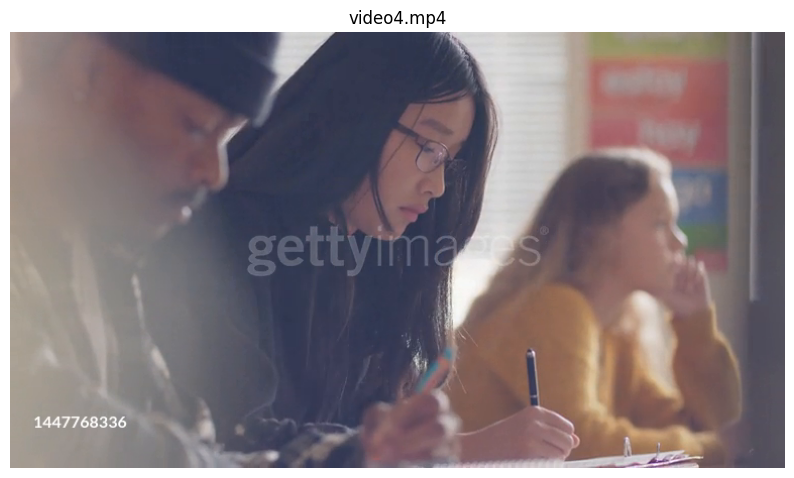

In [7]:
def read_middle_frame(video_path):
    cap = cv2.VideoCapture(str(video_path))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    middle_frame = max(total_frames // 2, 0)

    cap.set(cv2.CAP_PROP_POS_FRAMES, middle_frame)
    ok, frame = cap.read()
    cap.release()

    if not ok:
        return None

    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

for video_path in video_files:
    frame = read_middle_frame(video_path)

    if frame is None:
        print("Could not read:", video_path.name)
        continue

    plt.figure(figsize=(10, 6))
    plt.imshow(frame)
    plt.title(video_path.name)
    plt.axis("off")
    plt.show()

## 8. Load YOLO11

We use the pretrained **YOLO11n** model.

For this notebook, only COCO class `person = 0` is detected.


In [8]:
model = YOLO("yolo11n.pt")
print("YOLO11 model loaded successfully.")

YOLO11 model loaded successfully.


## 9. Test person detection on one frame

In [9]:
sample_video = video_files[0]

cap = cv2.VideoCapture(str(sample_video))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
sample_frame_index = max(total_frames // 2, 0)

cap.set(cv2.CAP_PROP_POS_FRAMES, sample_frame_index)
ok, frame = cap.read()
cap.release()

assert ok, "Could not read sample frame."

results = model.predict(
    source=frame,
    classes=[0],
    conf=0.35,
    verbose=False
)

result = results[0]

print("Detected persons:", len(result.boxes))

Detected persons: 4


## 10. Draw green bounding boxes manually

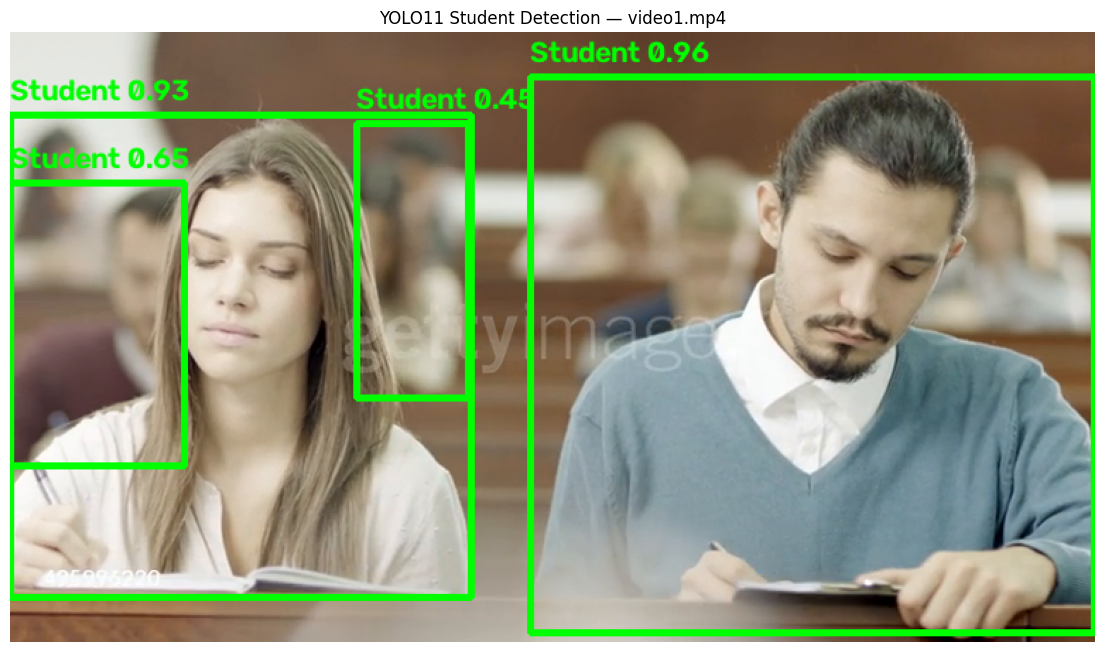

In [10]:
annotated_frame = frame.copy()

for box in result.boxes:
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
    confidence = float(box.conf[0])

    color = (0, 255, 0)

    cv2.rectangle(
        annotated_frame,
        (x1, y1),
        (x2, y2),
        color,
        3
    )

    label = f"Student {confidence:.2f}"

    cv2.putText(
        annotated_frame,
        label,
        (x1, max(y1 - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        color,
        2
    )

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB))
plt.title(f"YOLO11 Student Detection — {sample_video.name}")
plt.axis("off")
plt.show()

## 11. Process one complete video

This cell:
- reads every frame,
- detects persons,
- draws a green bounding box,
- saves the processed video to Drive.

There is **no tracking yet**.


In [11]:
INPUT_VIDEO = video_files[0]
OUTPUT_VIDEO = DETECTION_OUTPUT_DIR / f"{INPUT_VIDEO.stem}_detected.mp4"

cap = cv2.VideoCapture(str(INPUT_VIDEO))

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(
    str(OUTPUT_VIDEO),
    fourcc,
    fps,
    (width, height)
)

frame_count = 0

while True:
    ok, frame = cap.read()

    if not ok:
        break

    result = model.predict(
        source=frame,
        classes=[0],
        conf=0.35,
        verbose=False
    )[0]

    for box in result.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
        confidence = float(box.conf[0])

        cv2.rectangle(
            frame,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            3
        )

        cv2.putText(
            frame,
            f"Student {confidence:.2f}",
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

    writer.write(frame)
    frame_count += 1

    if frame_count % 50 == 0:
        print(f"Processed {frame_count}/{total_frames} frames")

cap.release()
writer.release()

print("Done.")
print("Saved to:", OUTPUT_VIDEO)

Processed 50/488 frames
Processed 100/488 frames
Processed 150/488 frames
Processed 200/488 frames
Processed 250/488 frames
Processed 300/488 frames
Processed 350/488 frames
Processed 400/488 frames
Processed 450/488 frames
Done.
Saved to: /content/drive/MyDrive/cheating tracking/outputs/detection/video1_detected.mp4


## 12. Preview the processed video in Colab

In [12]:
from IPython.display import Video, display

display(
    Video(
        str(OUTPUT_VIDEO),
        embed=True,
        width=900
    )
)

Output hidden; open in https://colab.research.google.com to view.

## 13. Optional — Process all uploaded videos

In [13]:
def detect_students_in_video(input_video, output_video, model, conf=0.35):
    cap = cv2.VideoCapture(str(input_video))

    if not cap.isOpened():
        print("Cannot open:", input_video)
        return

    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    writer = cv2.VideoWriter(
        str(output_video),
        fourcc,
        fps,
        (width, height)
    )

    while True:
        ok, frame = cap.read()

        if not ok:
            break

        result = model.predict(
            source=frame,
            classes=[0],
            conf=conf,
            verbose=False
        )[0]

        for box in result.boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
            confidence = float(box.conf[0])

            cv2.rectangle(
                frame,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                3
            )

            cv2.putText(
                frame,
                f"Student {confidence:.2f}",
                (x1, max(y1 - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (0, 255, 0),
                2
            )

        writer.write(frame)

    cap.release()
    writer.release()

    print("Saved:", output_video)

for video_path in video_files:
    output_path = DETECTION_OUTPUT_DIR / f"{video_path.stem}_detected.mp4"

    detect_students_in_video(
        video_path,
        output_path,
        model
    )

Saved: /content/drive/MyDrive/cheating tracking/outputs/detection/video1_detected.mp4
Saved: /content/drive/MyDrive/cheating tracking/outputs/detection/video2_detected.mp4
Saved: /content/drive/MyDrive/cheating tracking/outputs/detection/video3_detected.mp4
Saved: /content/drive/MyDrive/cheating tracking/outputs/detection/video4_detected.mp4
